# Imports

In [48]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# data1 = pd.read_csv("/content/user1_data.csv")
# data2 = pd.read_csv("/content/user2_data.csv")

In [49]:
data1 = pd.read_csv("/content/user1_data-2.csv")
data2 = pd.read_csv("/content/user2_data-2.csv")

#Data Visualiztion

In [50]:
data1.columns

Index(['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'st', 'lum'], dtype='object')

In [51]:
data1.shape

(19341, 8)

In [52]:
data2.columns

Index(['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'lum', 'temp', 'humd',
       'pres'],
      dtype='object')

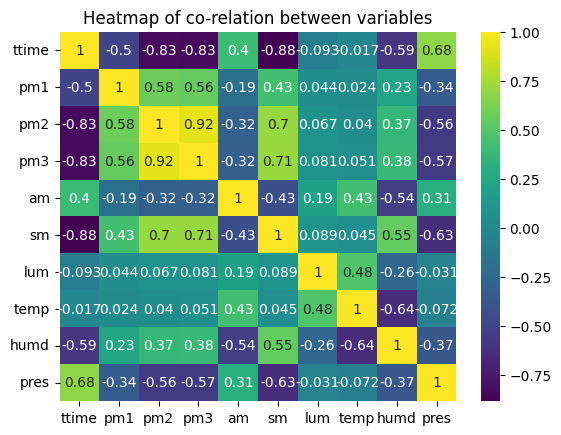

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data2.corr(),annot=True,cmap='viridis')
plt.title('Heatmap of co-relation between variables')
plt.show()

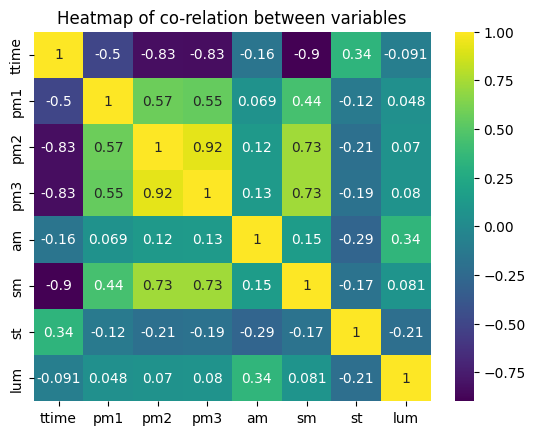

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data1.corr(),annot=True,cmap='viridis')
plt.title('Heatmap of co-relation between variables')
plt.show()

In [11]:
data1.tail()

,ttime,pm1,pm2,pm3,am,sm,st,lum
19336,2023-03-10 08:45:06,1.11,1.11,28.49,3.2,291.0,29.40,384.0
19337,2023-03-10 09:12:06,0.55,1.11,28.49,3.2,292.0,29.32,384.0
19338,2023-03-10 09:39:09,1.11,1.11,28.49,2.4,291.0,29.24,384.0
19339,2023-03-10 10:06:09,0.55,1.11,28.49,1.6,291.0,29.17,384.0
19340,2023-03-10 11:01:05,0.55,1.11,28.49,8.8,292.0,29.06,384.0


#Data Pre-Prosessing

In [56]:
data1['ttime']=pd.to_datetime(data1.ttime, format='%Y-%m-%d %H:%M:%S')
data1.set_index('ttime',inplace=True)
data1['day']=data1.index.day
data1['Month']=data1.index.month
data1['year']=data1.index.year
data1['hour']=data1.index.hour
data1['min']=(data1.index.minute//5)+1
data1.reset_index(inplace=True)
data1=data1.drop(['ttime'],axis=1)
data1

,pm1,pm2,pm3,am,sm,st,lum,day,Month,year,hour,min
0,3.66,0.00,0.22,2.93,7921.16,25.67,14773.35,18,7,2022,15,9
1,4.18,-0.00,0.46,4.96,7720.22,25.67,13991.22,18,7,2022,15,10
2,4.77,0.08,1.65,3.99,7636.10,25.50,13763.64,18,7,2022,15,11
3,5.38,0.06,0.00,4.67,7703.41,25.62,14263.19,18,7,2022,15,12
4,0.54,5.31,4.84,3.09,7926.96,25.67,15137.09,18,7,2022,16,1
...,...,...,...,...,...,...,...,...,...,...,...,...
19336,1.04,1.05,27.47,3.17,130.82,29.47,248.59,10,3,2023,8,10
19337,0.60,1.12,26.60,3.34,498.91,29.43,600.61,10,3,2023,9,3
19338,1.08,1.01,26.77,2.39,425.12,29.20,168.41,10,3,2023,9,8
19339,0.55,1.18,27.24,1.61,225.61,29.16,432.45,10,3,2023,10,2


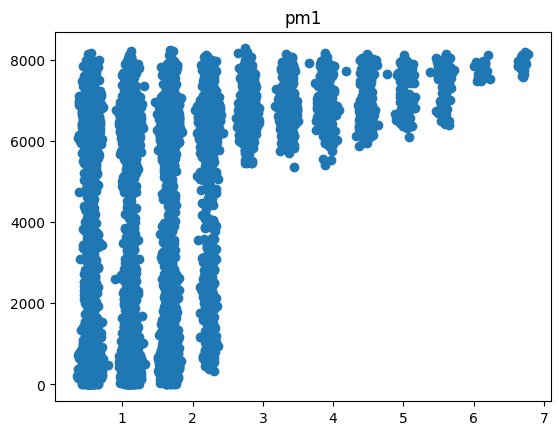

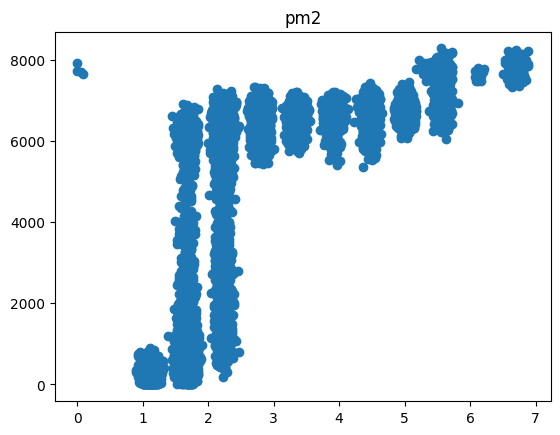

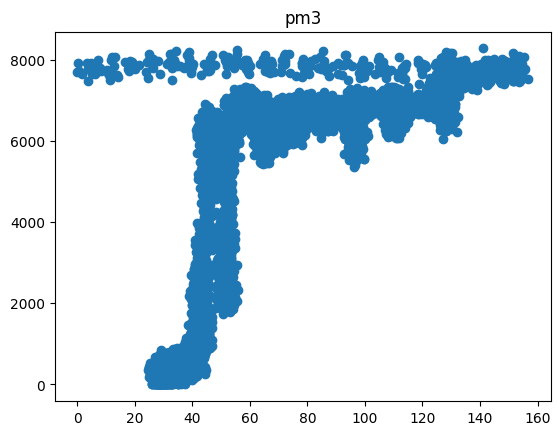

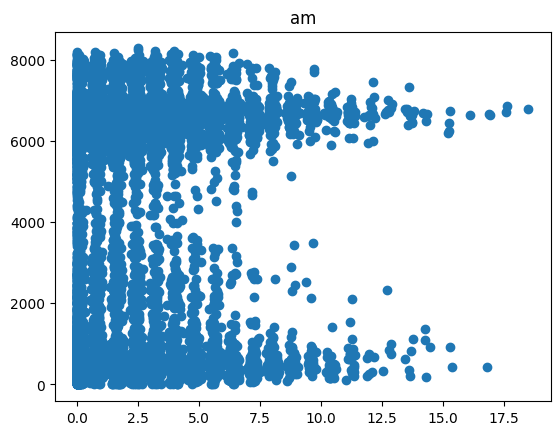

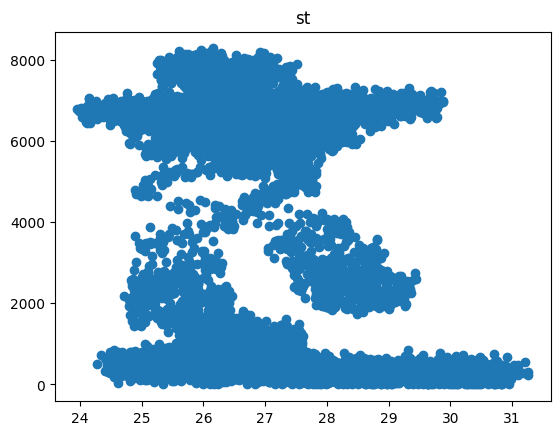

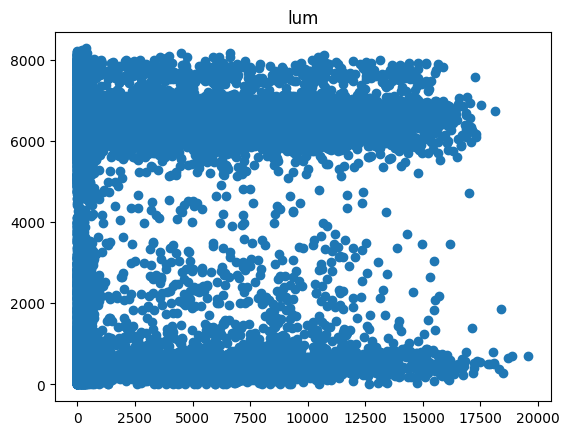

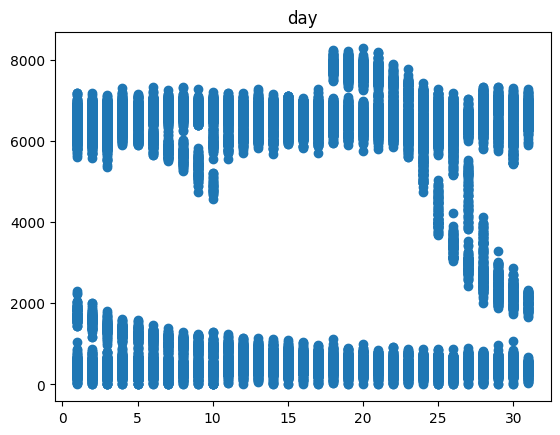

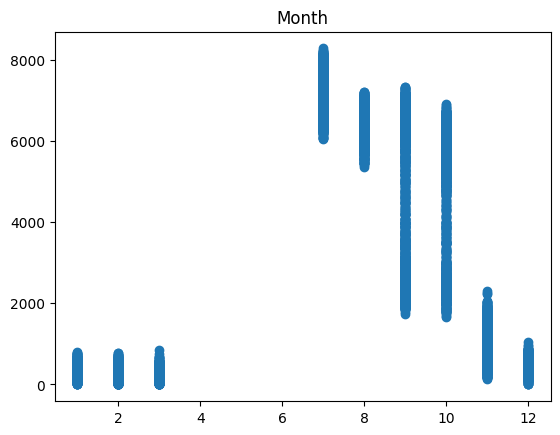

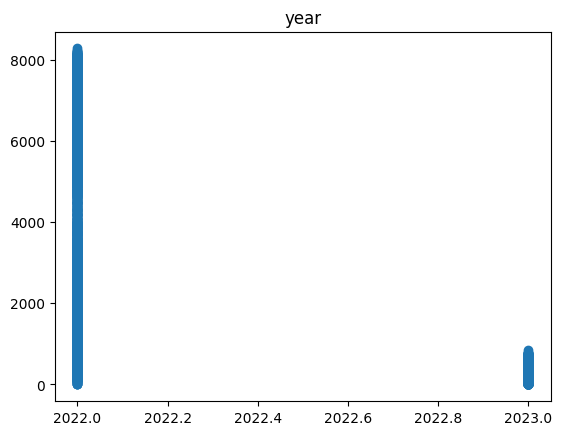

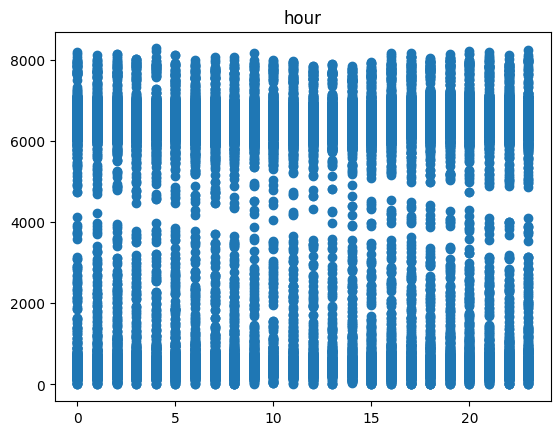

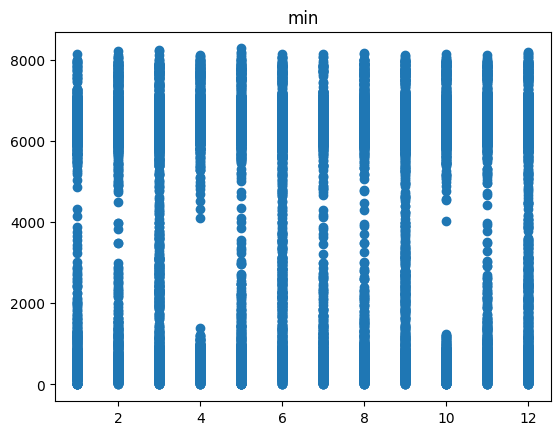

In [57]:
for i in data1.columns.drop('sm'):
  ypoints = data1['sm']
  plt.scatter(data1[i], ypoints)
  plt.title(i)
  plt.show()

In [58]:
data2['ttime']=pd.to_datetime(data2.ttime, format='%Y-%m-%d %H:%M:%S')
data2.set_index('ttime',inplace=True)
data2['day']=data2.index.day
data2['Month']=data2.index.month
data2['year']=data2.index.year
data2['hour']=data2.index.hour
data2['min']=(data2.index.minute//5)+1
data2.reset_index(inplace=True)
data2=data2.drop(['ttime'],axis=1)
data2

,pm1,pm2,pm3,am,sm,lum,temp,humd,pres,day,Month,year,hour,min
0,0.77,0.05,0.00,0.14,7585.47,6963.04,22.90,91.14,92861.75,18,7,2022,15,8
1,1.38,0.01,2.84,0.14,7591.22,10358.79,23.48,87.46,92852.82,18,7,2022,15,9
2,1.93,0.00,0.13,0.01,7710.41,12524.68,23.59,87.45,92851.87,18,7,2022,15,10
3,2.55,0.08,0.00,-0.00,7434.80,8387.61,23.45,83.28,92855.16,18,7,2022,15,11
4,0.48,2.53,2.21,0.01,7517.39,4182.95,23.15,86.22,92801.24,18,7,2022,15,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20161,0.51,1.13,26.35,3.25,233.01,6441.55,26.99,32.15,93584.80,10,3,2023,8,12
20162,1.18,1.06,26.34,3.15,437.62,7163.92,28.39,29.21,93589.60,10,3,2023,9,6
20163,1.72,1.18,27.99,4.77,296.99,7607.16,29.86,22.51,93592.92,10,3,2023,9,12
20164,0.55,1.71,29.51,4.01,330.06,8617.77,31.65,21.23,93558.10,10,3,2023,10,5


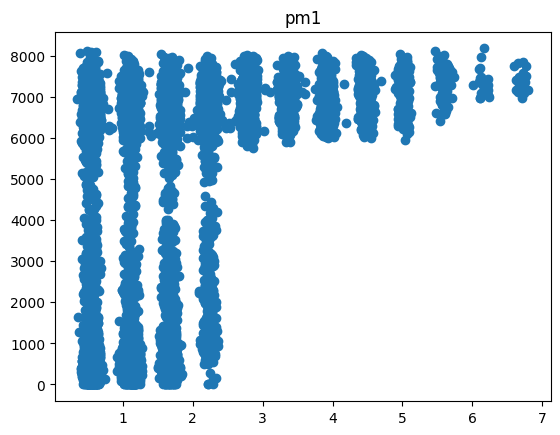

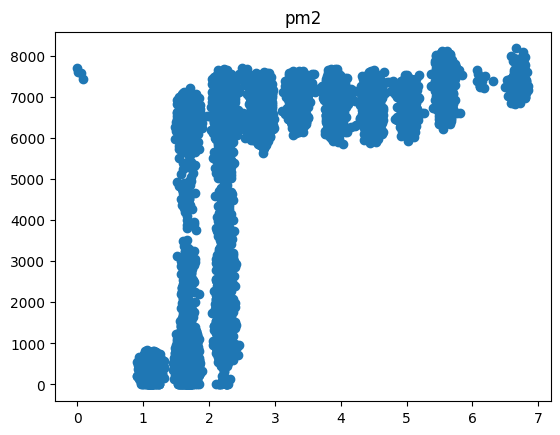

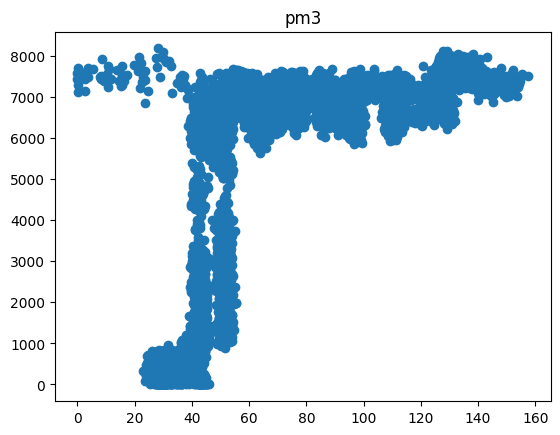

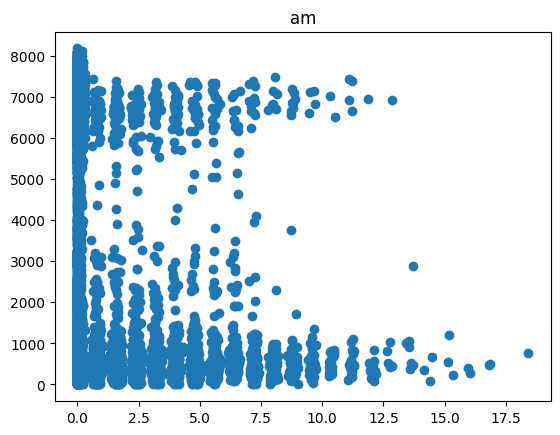

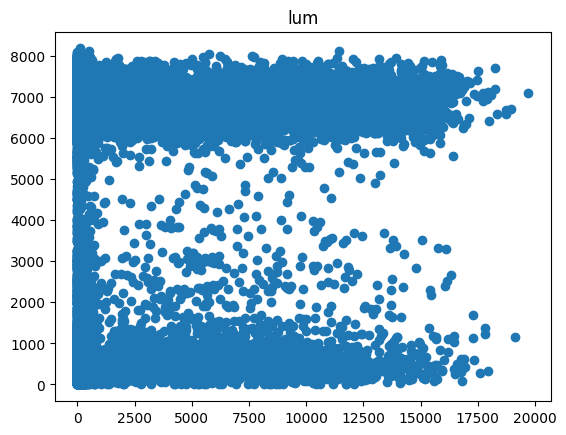

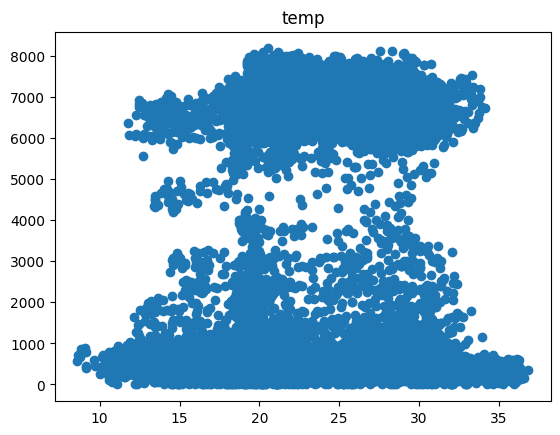

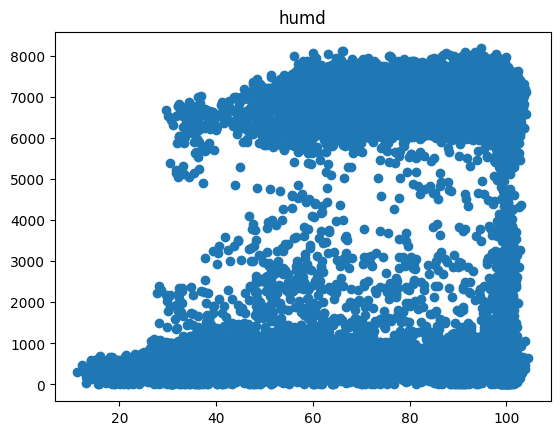

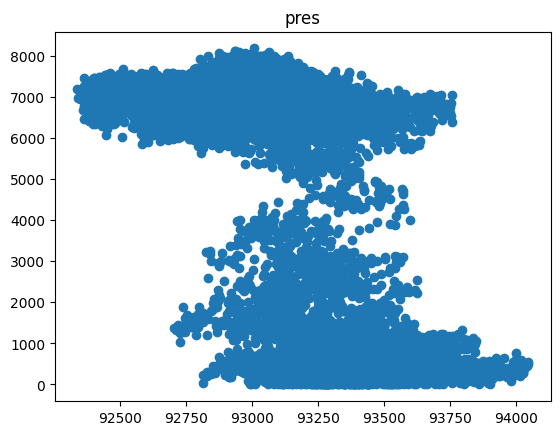

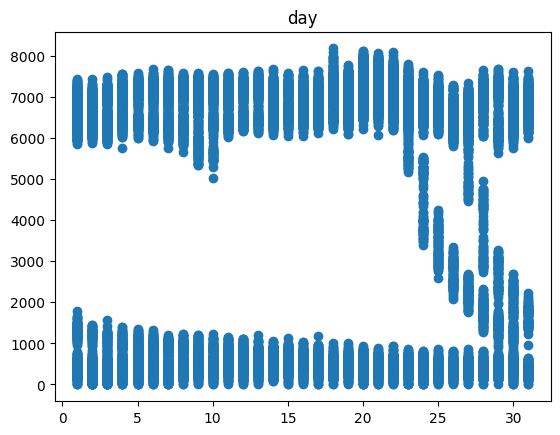

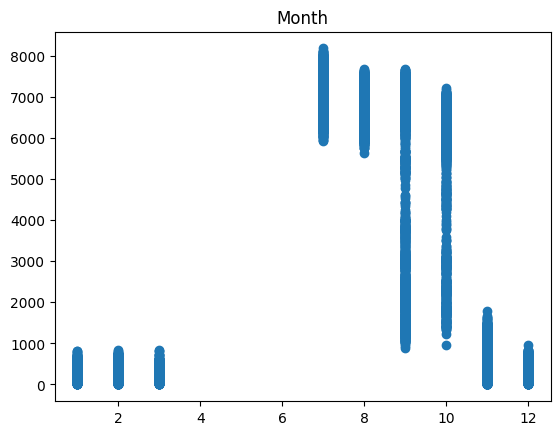

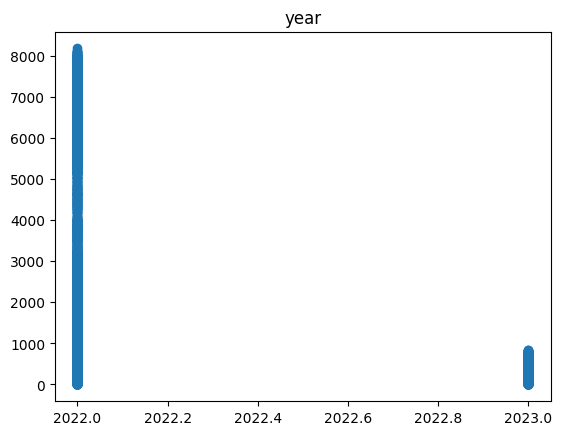

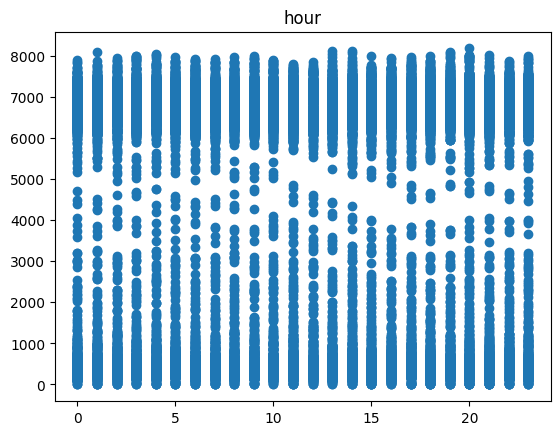

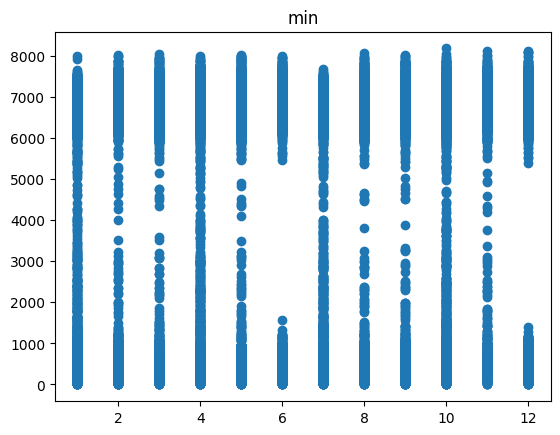

In [59]:
for i in data2.columns.drop('sm'):
  ypoints = data2['sm']
  plt.scatter( data2[i],ypoints)
  plt.title(i)
  plt.show()

#Combine Data

In [60]:
data_comb = data1.merge( data2, on=['day','Month','year','hour','min'], how='outer')
data_comb

,pm1_x,pm2_x,pm3_x,am_x,sm_x,st,lum_x,day,Month,year,...,min,pm1_y,pm2_y,pm3_y,am_y,sm_y,lum_y,temp,humd,pres
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,2023,...,1,0.50,1.08,34.88,0.00,204.21,169.87,17.13,92.29,93737.89
1,0.63,1.64,33.98,0.00,441.59,27.51,52.37,1,1,2023,...,5,1.08,1.15,33.63,0.06,500.88,0.00,16.93,93.76,93694.51
2,1.02,1.58,32.96,0.02,508.89,27.45,339.68,1,1,2023,...,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,2023,...,10,1.67,1.20,36.48,0.00,330.92,335.15,16.69,93.35,93663.31
4,0.60,1.20,33.11,0.00,420.51,27.39,341.26,1,1,2023,...,2,0.51,1.73,34.36,0.04,318.42,0.00,16.81,90.14,93696.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33033,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,12,2022,...,11,1.61,1.10,34.76,0.00,194.29,89.12,18.18,86.98,93783.57
33034,0.56,1.71,34.08,0.09,414.52,27.63,0.00,31,12,2022,...,3,0.49,1.65,36.10,0.06,335.04,0.00,18.01,85.60,93746.09
33035,1.13,1.69,32.86,0.07,125.20,27.54,62.89,31,12,2022,...,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,12,2022,...,8,1.07,1.61,32.64,0.00,349.21,51.94,17.35,90.74,93724.08


In [61]:
# data_comb.columns
print('Count of missing values:\n',data_comb.shape[0]-data_comb.count())

Count of missing values:
 pm1_x    13697
pm2_x    13697
pm3_x    13697
am_x     13697
sm_x     13697
st       13697
lum_x    13697
day          0
Month        0
year         0
hour         0
min          0
pm1_y    12872
pm2_y    12872
pm3_y    12872
am_y     12872
sm_y     12872
lum_y    12872
temp     12872
humd     12872
pres     12872
dtype: int64


In [62]:
data_comb["pm1"] = data_comb[['pm1_x','pm1_y']].mean(axis=1)
data_comb["pm2"] = data_comb[['pm2_x','pm2_y']].mean(axis=1)
data_comb["pm3"] = data_comb[['pm3_x','pm3_y']].mean(axis=1)
data_comb["am"] = data_comb[['am_x','am_y']].mean(axis=1)
data_comb["sm"] = data_comb[['sm_x','sm_y']].mean(axis=1)
data_comb["lum"] = data_comb[['lum_x','lum_y']].mean(axis=1)
data_comb = data_comb.drop(['pm1_x','pm1_y','pm2_x','pm2_y','pm3_x','pm3_y','am_x','am_y','sm_x','sm_y','lum_x','lum_y'],axis=1)

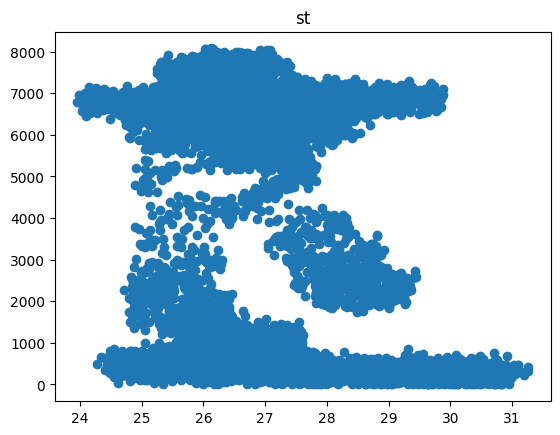

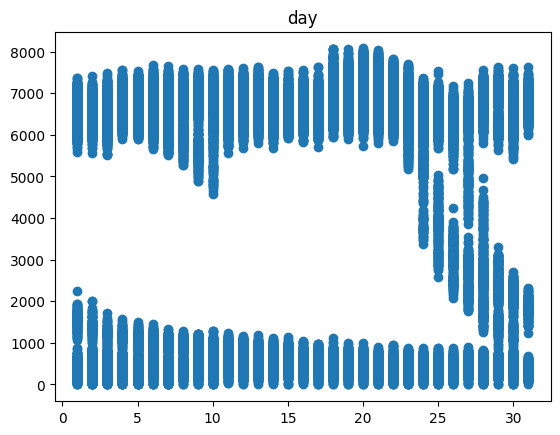

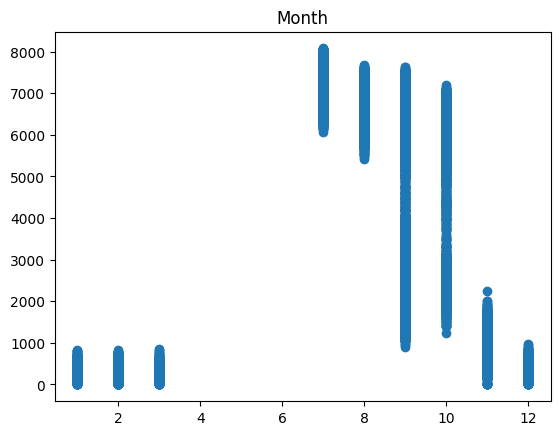

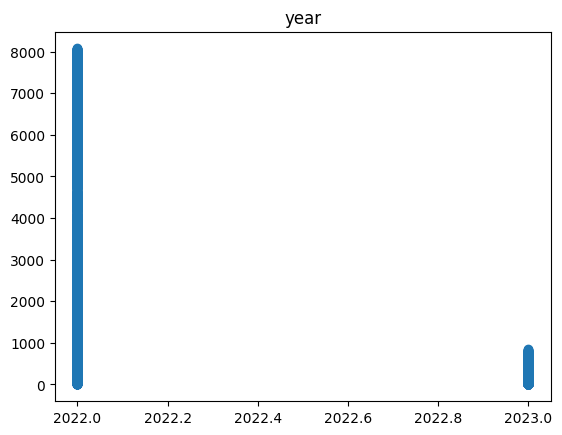

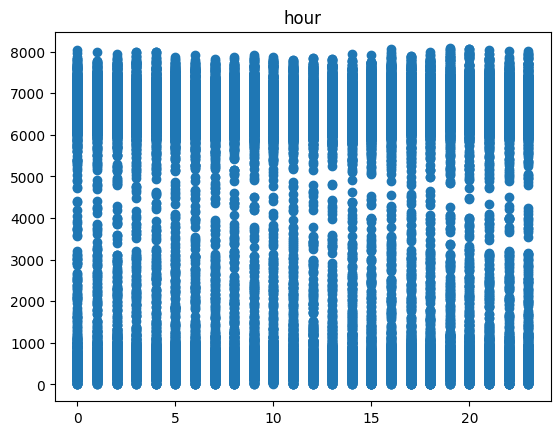

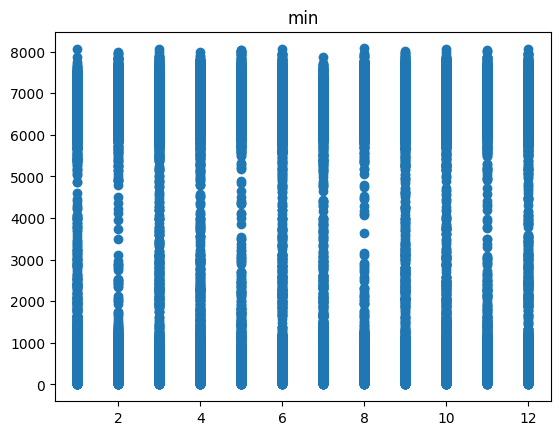

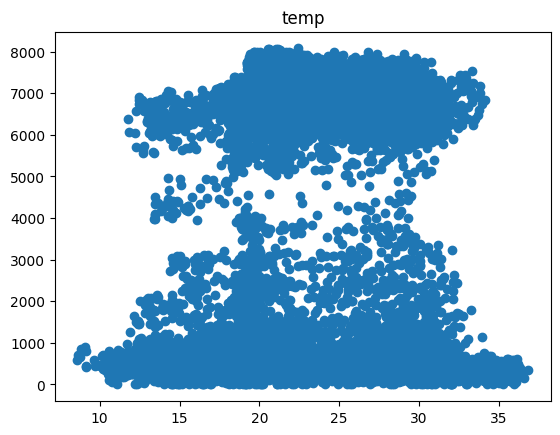

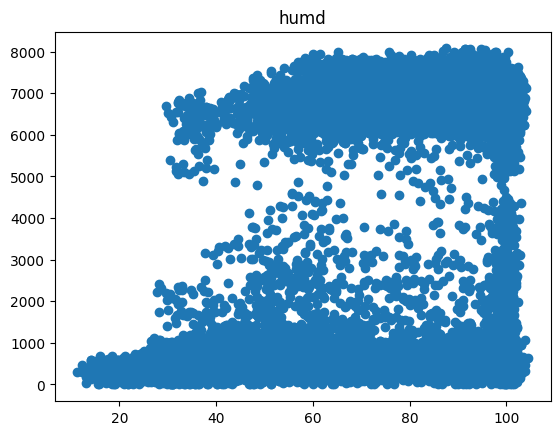

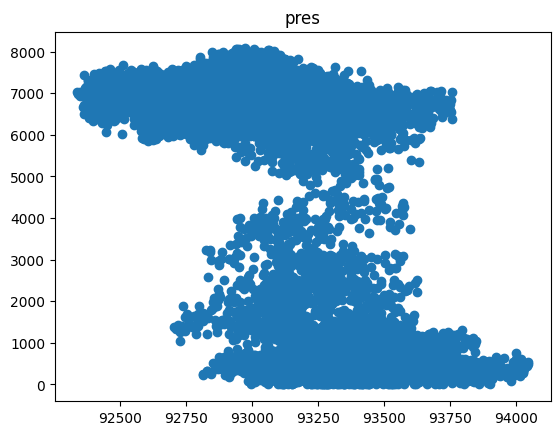

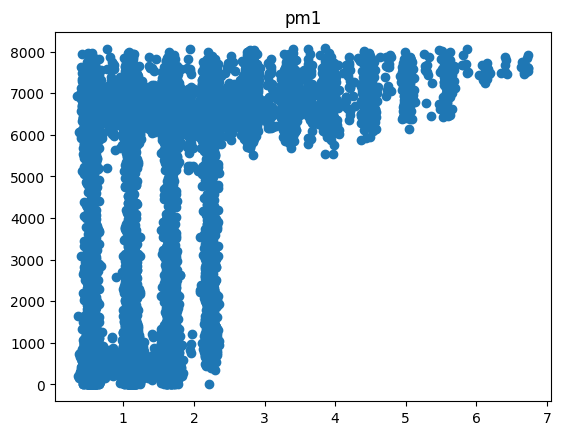

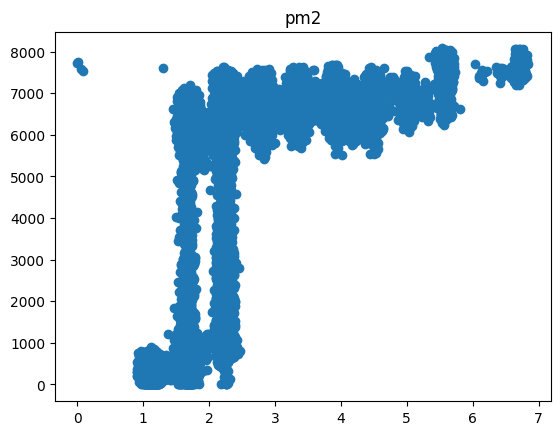

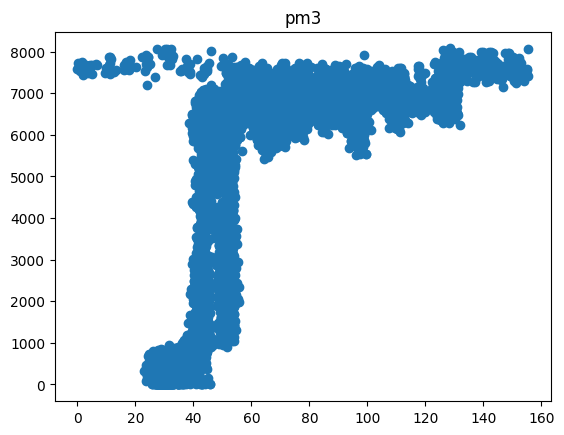

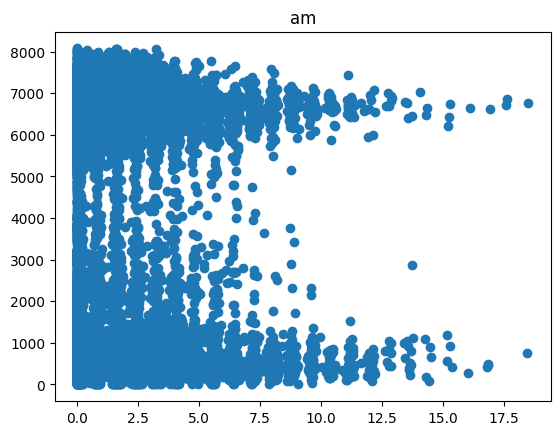

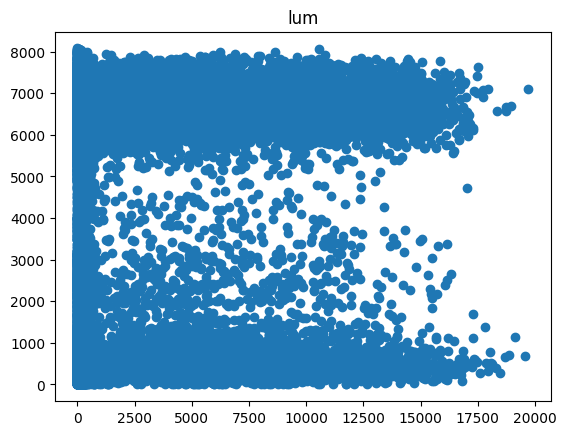

In [63]:
for i in data_comb.columns.drop('sm'):
  ypoints = data_comb['sm']
  plt.scatter(data_comb[i], ypoints)
  plt.title(i)
  plt.show()

In [64]:
data_comb.isnull().sum()

,0
st,13697
day,0
Month,0
year,0
hour,0
min,0
temp,12872
humd,12872
pres,12872
pm1,0


In [65]:
data_comb.describe()

,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
count,19341.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,20166.000000,20166.000000,20166.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000
mean,26.852952,16.203644,8.086809,2022.162994,11.527998,6.505388,22.625794,78.332037,93154.368802,1.534749,2.475793,57.105526,1.406032,4123.905259,2838.075745
std,1.165095,9.026522,3.128060,0.369366,6.992460,3.456231,4.669722,24.045032,291.286511,0.977317,1.185125,26.186926,2.079540,3010.873022,4140.540996
min,23.960000,1.000000,1.000000,2022.000000,0.000000,1.000000,8.600000,11.310000,92339.550000,0.350000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.100000,8.000000,7.000000,2022.000000,5.000000,4.000000,19.960000,61.680000,92976.542500,0.640000,1.650000,37.151250,0.000000,538.808750,16.391250
50%,26.710000,17.000000,9.000000,2022.000000,12.000000,6.000000,21.450000,88.200000,93152.630000,1.170000,2.210000,48.770000,0.210000,6153.172500,294.335000
75%,27.390000,24.000000,10.000000,2022.000000,18.000000,9.000000,26.090000,99.140000,93349.775000,2.090000,3.260000,70.910000,2.300000,6766.257500,4987.312500
max,31.260000,31.000000,12.000000,2023.000000,23.000000,12.000000,36.860000,104.540000,94047.820000,6.735000,6.845000,155.535000,18.490000,8074.520000,19705.190000


#Model Runn Prep

In [66]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.ensemble import RandomForestRegressor


In [67]:
data_comb.to_csv('/content/data_comb.csv')

In [68]:
df1=pd.read_csv('/content/data_comb.csv')
# df1=df1.drop(['temp' ,'humd','st', 'pres'],axis=1)

In [69]:
df1.head()

,Unnamed: 0,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
0,0,NaN,1,1,2023,0,1,17.13,92.29,93737.89,0.500,1.080,34.880,0.00,204.210,169.870
1,1,27.51,1,1,2023,0,5,16.93,93.76,93694.51,0.855,1.395,33.805,0.03,471.235,26.185
2,2,27.45,1,1,2023,0,9,NaN,NaN,NaN,1.020,1.580,32.960,0.02,508.890,339.680
3,3,NaN,1,1,2023,0,10,16.69,93.35,93663.31,1.670,1.200,36.480,0.00,330.920,335.150
4,4,27.39,1,1,2023,1,2,16.81,90.14,93696.54,0.555,1.465,33.735,0.02,369.465,170.630


In [70]:
df1.isnull().sum()

,0
Unnamed: 0,0
st,13697
day,0
Month,0
year,0
hour,0
min,0
temp,12872
humd,12872
pres,12872


In [71]:
X=df1.drop('sm',axis=1)
y=df1['sm']

# Random Forest Regressor

In [72]:
def rfr_score_dataset(X_train, X_test, y_train, y_test):
  forest = RandomForestRegressor(n_estimators=1000,
                                criterion='squared_error',
                                random_state=1,
                                n_jobs=-1)
  forest.fit(X_train, y_train)
  y_test_pred = forest.predict(X_test)

  print("MSE : ",(mean_squared_error(y_test, y_test_pred)))
  print("MAE : ",mean_absolute_error(y_test, y_test_pred))
  print('score:', forest.score(X_test, y_test))
  print("R square : ",r2_score(y_test, y_test_pred, force_finite=False))

# # for t in range(5,9,1) :
#   # for r in range(0,100,20) :
# X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=80, test_size=20,random_state=32)
# print("train size : 80  random state : 32")
# print(rfr_score_dataset( X_train, X_valid, y_train, y_valid))

##RFR Imputation
 * use of Imputation method to clean Null Values

In [73]:
from sklearn.impute import SimpleImputer

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)


# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

print("MAE from Approach 2 (Imputation):")
print(rfr_score_dataset(imputed_X_train, imputed_X_valid, y_train, y_valid))

MAE from Approach 2 (Imputation):
MSE :  31874.140414444166
MAE :  133.65273849273618
score: 0.9964843757909088
R square :  0.9964843757909088
None


* MAE :  32.106408898305084
* score: 0.9995056557239824

In [74]:
#train size : 80% random state : 60
# MSE :  3203.7463507195666
# score: 0.9996242501807985

##RFR An Extension to Imputation

*   use of Imputation method to clean Null Values
*   And column is Added to classify Changed value



In [75]:
# Make copy to avoid changing original data (when imputing)
X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

print("MAE from Approach 3 (An Extension to Imputation):")
print(rfr_score_dataset(imputed_X_train_plus, imputed_X_valid_plus, y_train, y_valid))

MAE from Approach 3 (An Extension to Imputation):
MSE :  32354.488619079293
MAE :  133.41324645127105
score: 0.9964313947926747
R square :  0.9964313947926747
None


* MAE :  31.790357067191284
* score: 0.99951847418523

#RFR Pipeline

In [76]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score


## RFR pipeline Imputation

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

# Bundle preprocessing and modeling code in a pipeline
my_pipeline = Pipeline(steps=[('preprocessor', SimpleImputer(strategy="mean")),
                              ('model', RandomForestRegressor(n_estimators=1000, random_state=32))
                             ])

# Preprocessing of training data, fit model
my_pipeline.fit(imputed_X_train, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid, y_valid))

MAE: 133.61093944839584
0.996486230722846


##RFR pipeline An Extension to Imputation

In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

# Preprocessing of training data, fit model
my_pipeline.fit(imputed_X_train_plus, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid_plus)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid_plus, y_valid))

MAE: 133.20865652012702
0.9964539280952759


#XG Boost


 ## XG Boost Imputation

In [79]:
from xgboost import XGBRegressor
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

my_model1 = XGBRegressor(early_stopping_rounds=5,n_estimators=1000, learning_rate=0.05, n_jobs=4)
my_model1.fit(imputed_X_train, y_train,
             eval_set=[(imputed_X_valid, y_valid)],
             verbose=False)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=4, num_parallel_tree=None, ...)

In [80]:
preds = my_model1.predict(imputed_X_valid)
print(mean_absolute_error(y_valid, preds))
print(my_model1.score(imputed_X_valid, y_valid))

147.42877716978873
0.9949289911405277


## XG Boost An Extension to Imputation




In [81]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

my_model = XGBRegressor(early_stopping_rounds=5,n_estimators=1000, learning_rate=0.05, n_jobs=4)
my_model.fit(imputed_X_train_plus, y_train,
             eval_set=[(imputed_X_valid_plus, y_valid)],
             verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=4, num_parallel_tree=None, ...)

In [82]:
preds = my_model.predict(imputed_X_valid_plus)
print(mean_absolute_error(y_valid, preds))
print(my_model.score(imputed_X_valid_plus, y_valid))

146.99948239120963
0.9948693588685453


In [83]:
# 44.41299256285513
# 99.92987124951946

# MAE: 36.268992130750604
# 99.94174852973395

# RESULT (comparing all result)

****
****
***Random Forest Regressor***
****
****
**RFR Imputation**
* MAE : 32.106408898305084
* score: 0.9995056557239824
*****
**RFR An Extension to Imputation**
* MAE :  31.790357067191284
* score: 0.99951847418523
****
****
***RFR Pipeline***
****
****
**RFR Pipeline Imputation**
* MAE: 32.094662076271185
* score: 0.9995066681120112
****
**RFR Pipeline An Extension to Imputation**
* MAE: 31.739522397094426
* score: 0.9995207551616186
****
****
***XG Boost***
****
****
**XG Boost Imputation**
* MAE: 40.77477760407307
* score: 0.9992572415266866
****
**XG Boost An Extension to Imputation**
* MAE: 43.111823557652805
* score: 0.9992541126453306
****
****

# BEST MODEL

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

# Bundle preprocessing and modeling code in a pipeline
my_pipeline = Pipeline(steps=[('preprocessor', SimpleImputer(strategy="mean")),
                              ('model', RandomForestRegressor(n_estimators=1000, random_state=32))
                             ])

# Preprocessing of training data, fit model
my_pipeline.fit(imputed_X_train_plus, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid_plus)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid_plus, y_valid))

KeyboardInterrupt: 